In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

1. Определение функции Била и её градиента

In [2]:
def beale_function(x, y):
    """
    Вычисляет значение функции Била.
    """
    term1 = (1.5 - x + x * y)**2
    term2 = (2.25 - x + x * y**2)**2
    term3 = (2.625 - x + x * y**3)**2
    return term1 + term2 + term3

def beale_gradient(x, y):
    """
    Вычисляет градиент (частные производные) функции Била.
    Возвращает кортеж (df/dx, df/dy).
    """
    # Производная по x
    # d/dx = 2*(1.5 - x + xy)*(-1 + y) + 2*(2.25 - x + xy^2)*(-1 + y^2) + 2*(2.625 - x + xy^3)*(-1 + y^3)
    dx = (2 * (1.5 - x + x*y) * (-1 + y) +
          2 * (2.25 - x + x*y**2) * (-1 + y**2) +
          2 * (2.625 - x + x*y**3) * (-1 + y**3))
    
    # Производная по y
    # d/dy = 2*(1.5 - x + xy)*(x) + 2*(2.25 - x + xy^2)*(2xy) + 2*(2.625 - x + xy^3)*(3xy^2)
    dy = (2 * (1.5 - x + x*y) * (x) +
          2 * (2.25 - x + x*y**2) * (2 * x * y) +
          2 * (2.625 - x + x*y**3) * (3 * x * y**2))
    
    return np.array([dx, dy])

2. Реализация метода наискорейшего градиентного спуска

In [23]:
def gradient_descent(start_point, learning_rate=0.01, tolerance=1e-6, max_iter=100000):
    """
    Метод наискорейшего градиентного спуска.
    """
    path = [np.array(start_point, dtype=float)]
    values = [beale_function(start_point[0], start_point[1])]
    
    current_point = np.array(start_point, dtype=float)
    iteration = 0
    reason = "max_iter"
    
    for i in range(max_iter):
        iteration = i
        grad = beale_gradient(current_point[0], current_point[1])
        
        # Проверка на сходимость (норма градиента)
        if np.linalg.norm(grad) < tolerance:
            reason = "converged"
            print(f"Сходимость достигнута на итерации {i}")
            break
            
        # Обновление точки: шаг против градиента
        # Для "наискорейшего" спуска можно подбирать шаг, но здесь используем фиксированный
        # с условием уменьшения при необходимости (упрощенно)
        next_point = current_point - learning_rate * grad
        
        # Простая адаптация шага: если значение функции выросло, уменьшаем шаг
        if beale_function(next_point[0], next_point[1]) > values[-1]:
            learning_rate *= 0.5
            continue

        current_point = next_point
        path.append(current_point)
        values.append(beale_function(current_point[0], current_point[1]))
    else:
        # Этот блок выполнится, если цикл завершился без break (достигнут max_iter)
        print(f"Достигнут максимум итераций ({max_iter}). Сходимость не достигнута.")

    return np.array(path), np.array(values), iteration, reason

# Параметры запуска
start_pt = [-2.0, -2.0]  # Начальная точка (можно выбрать любую в пределах [-4.5, 4.5])
# Функция Била имеет глобальный минимум в точке (3, 0.5) со значением 0.
# Если начать из (-2, -2), алгоритм должен прийти к минимуму.

path, error_history, n_iter, stop_reason = gradient_descent(start_pt, learning_rate=0.001, max_iter=100000)

print(f"Начальная точка: {start_pt}")
print(f"Найденный минимум (x, y): {path[-1]}")
print(f"Значение функции в минимуме: {error_history[-1]}")
print(f"Всего итераций: {n_iter}")
print(f"Причина остановки: {stop_reason}")


Сходимость достигнута на итерации 38789
Начальная точка: [-2.0, -2.0]
Найденный минимум (x, y): [2.99999678 0.4999992 ]
Значение функции в минимуме: 1.658401908577492e-12
Всего итераций: 38789
Причина остановки: converged


3. Визуализация

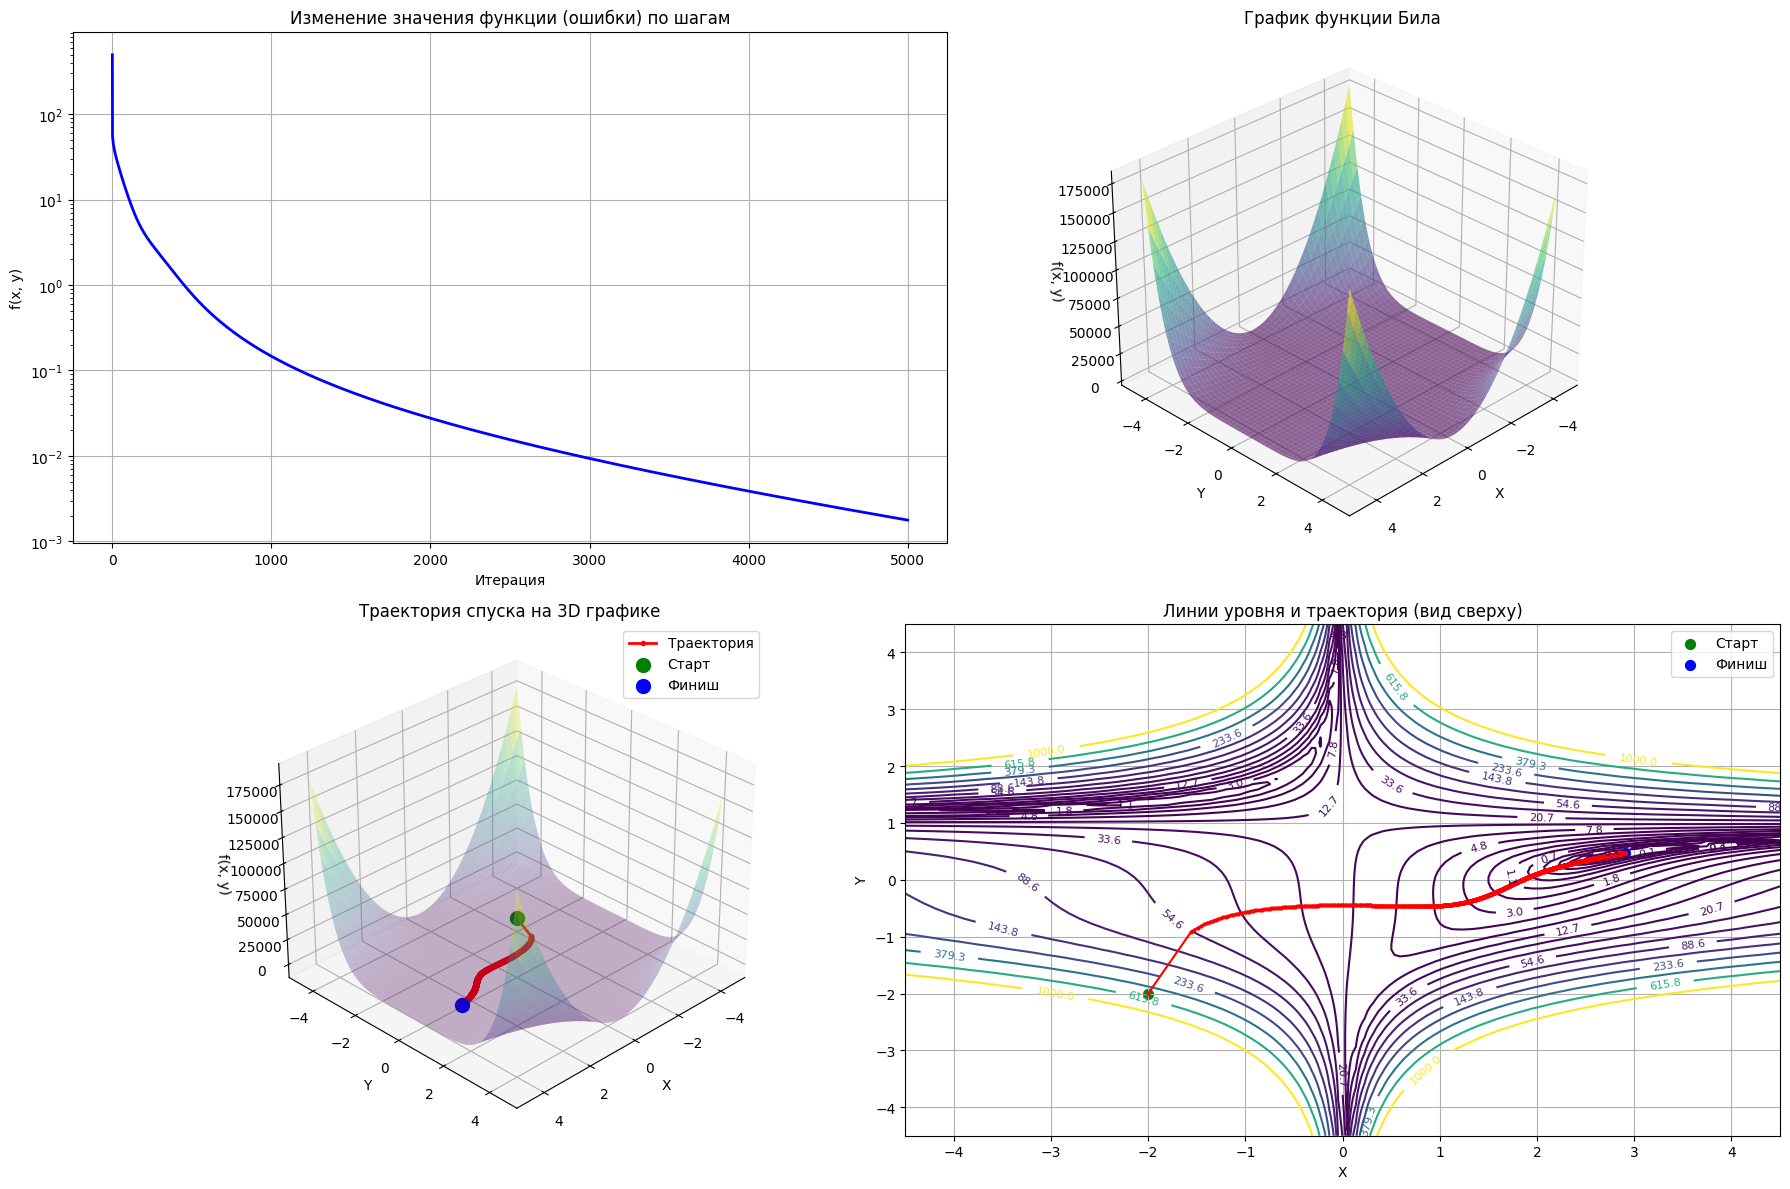

In [18]:
# Создаем сетку для 3D графика
x_range = np.linspace(-4.5, 4.5, 100)
y_range = np.linspace(-4.5, 4.5, 100)
X, Y = np.meshgrid(x_range, y_range)
Z = beale_function(X, Y)

fig = plt.figure(figsize=(18, 12))

# --- График 1: Изменение ошибки по шагам ---
ax1 = fig.add_subplot(2, 2, 1)
ax1.plot(error_history, color='blue', linewidth=2)
ax1.set_title('Изменение значения функции (ошибки) по шагам')
ax1.set_xlabel('Итерация')
ax1.set_ylabel('f(x, y)')
ax1.grid(True)
ax1.set_yscale('log') # Логарифмическая шкала часто удобнее для ошибки

# --- График 2: 3D поверхность функции ---
ax2 = fig.add_subplot(2, 2, 2, projection='3d')
surf = ax2.plot_surface(X, Y, Z, cmap='viridis', alpha=0.6, edgecolor='none')
ax2.set_title('График функции Била')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('f(x, y)')
ax2.view_init(elev=30, azim=45) # Настройка угла обзора

# --- График 3: Траектория движения на 3D графике ---
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
# Рисуем поверхность
ax3.plot_surface(X, Y, Z, cmap='viridis', alpha=0.3, edgecolor='none')
# Рисуем траекторию
path_x = path[:, 0]
path_y = path[:, 1]
path_z = error_history
ax3.plot(path_x, path_y, path_z, color='red', marker='o', markersize=3, linewidth=2, label='Траектория')
# Отмечаем старт и финиш
ax3.scatter(path_x[0], path_y[0], path_z[0], color='green', s=100, label='Старт', zorder=5)
ax3.scatter(path_x[-1], path_y[-1], path_z[-1], color='blue', s=100, label='Финиш', zorder=5)

ax3.set_title('Траектория спуска на 3D графике')
ax3.set_xlabel('X')
ax3.set_ylabel('Y')
ax3.set_zlabel('f(x, y)')
ax3.legend()
ax3.view_init(elev=30, azim=45)

# --- График 4: Линии уровня (Contour) с траекторией ---
ax4 = fig.add_subplot(2, 2, 4)
cp = ax4.contour(X, Y, Z, levels=np.logspace(-1, 3, 20), cmap='viridis')
ax4.clabel(cp, inline=True, fontsize=8)
ax4.plot(path_x, path_y, color='red', marker='o', markersize=2, linewidth=1.5)
ax4.scatter(path_x[0], path_y[0], color='green', s=50, label='Старт')
ax4.scatter(path_x[-1], path_y[-1], color='blue', s=50, label='Финиш')
ax4.set_title('Линии уровня и траектория (вид сверху)')
ax4.set_xlabel('X')
ax4.set_ylabel('Y')
ax4.legend()
ax4.grid(True)

plt.tight_layout()
plt.show()